<a href="https://colab.research.google.com/github/mailtotapasishah-cloud/sampleprojects/blob/main/Smart_Energy_Usage_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart Home Energy Usage Level Prediction

**Aim:** Predict whether household electricity usage is Low, Medium or High.

**Dataset:** `smart_energy_usage_dataset.csv` — one synthetic dataset containing 900 sample records.

**Algorithms:** KNN, Decision Tree, Logistic Regression, Random Forest and SVM.

> This dataset is generated for educational practice. It is not real smart-meter data.

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

## 2. Load the single dataset

In [2]:
data = pd.read_csv("smart_energy_usage_dataset.csv")
print(data.head())
print("\\nDataset shape:", data.shape)
print("\\nMissing values:", data.isnull().sum().sum())
print("\\nUsage level counts:")
print(data["usage_level"].value_counts())

   hour_of_day day_type  temperature_c  number_of_occupants  \
0           21  Weekday           16.8                    2   
1            8  Weekday           18.8                    1   
2           22  Weekend           25.3                    5   
3           13  Weekday           41.8                    1   
4            7  Weekday           32.4                    6   

   appliances_in_use air_conditioner  energy_usage_kwh usage_level  
0                  9              No              1.82      Medium  
1                  4              No              1.04         Low  
2                  5             Yes              2.65      Medium  
3                 10              No              0.82         Low  
4                 12             Yes              3.57        High  
\nDataset shape: (900, 8)
\nMissing values: 0
\nUsage level counts:
usage_level
Medium    526
Low       317
High       57
Name: count, dtype: int64


## 3. Separate input and output

In [3]:
# The energy_usage_kwh column is excluded to avoid using the value
# from which the usage_level label was created.
X = data.drop(["usage_level", "energy_usage_kwh"], axis=1)
y = data["usage_level"]

numeric_columns = X.select_dtypes(include=["int64", "float64"]).columns
categorical_columns = X.select_dtypes(include=["object"]).columns

print("Input features:", list(X.columns))
print("Output label: usage_level")

Input features: ['hour_of_day', 'day_type', 'temperature_c', 'number_of_occupants', 'appliances_in_use', 'air_conditioner']
Output label: usage_level


## 4. Split the dataset

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 720
Testing records: 180


## 5. Prepare numeric and categorical data

In [5]:
preprocessor = ColumnTransformer([
    ("numbers", StandardScaler(), numeric_columns),
    ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
])

## 6. Train and test five algorithms

In [6]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC()
}

results = []
predictions = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("prepare", preprocessor),
        ("model", model)
    ])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    predictions[name] = pred
    accuracy = accuracy_score(y_test, pred)
    results.append({"Algorithm": name, "Accuracy (%)": accuracy * 100})
    print(name, "Accuracy:", round(accuracy * 100, 2), "%")

KNN Accuracy: 82.22 %
Decision Tree Accuracy: 80.56 %
Logistic Regression Accuracy: 83.89 %
Random Forest Accuracy: 85.0 %
SVM Accuracy: 83.33 %


## 7. Compare model accuracy

          Algorithm  Accuracy (%)
                KNN     82.222222
      Decision Tree     80.555556
Logistic Regression     83.888889
      Random Forest     85.000000
                SVM     83.333333


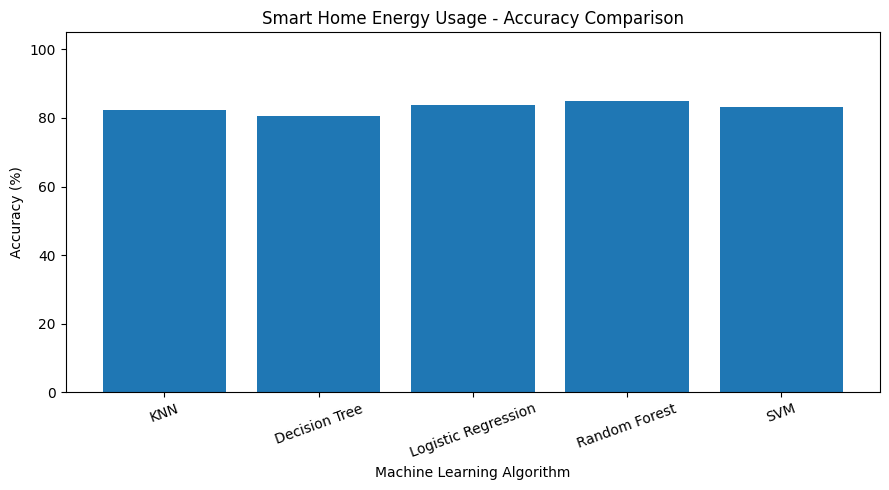

\nBest algorithm: Random Forest
Best accuracy: 85.0 %


In [7]:
results = pd.DataFrame(results)
print(results.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.bar(results["Algorithm"], results["Accuracy (%)"])
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Accuracy (%)")
plt.title("Smart Home Energy Usage - Accuracy Comparison")
plt.ylim(0, 105)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

best = results.loc[results["Accuracy (%)"].idxmax()]
print("\\nBest algorithm:", best["Algorithm"])
print("Best accuracy:", round(best["Accuracy (%)"], 2), "%")

## 8. Classification report

In [8]:
best_name = best["Algorithm"]
print("Classification report for:", best_name)
print(classification_report(y_test, predictions[best_name]))

Classification report for: Random Forest
              precision    recall  f1-score   support

        High       1.00      0.18      0.31        11
         Low       0.85      0.88      0.86        64
      Medium       0.85      0.90      0.88       105

    accuracy                           0.85       180
   macro avg       0.90      0.65      0.68       180
weighted avg       0.86      0.85      0.84       180



## 9. Conclusion

In this project, one smart-home energy dataset was used to classify household electricity usage into Low, Medium or High categories. Five classification algorithms were trained and tested, and their accuracy scores were compared.

**Dataset note:** All records are synthetic examples generated for educational practice.